# RS05 — VaR Reliability Monitoring: Final Research Review

## Final notebook / professor version

**Scope:** only the final RS05 source files and final COVID outputs supplied with this project.

### Central research question

> **Can a causal reliability layer warn that an existing 5% VaR model is likely to deteriorate or suffer future coverage failure before the failure becomes observable in realized outcomes?**

The final system evaluates four VaR models:

- EWMA
- GARCH-t
- Historical Simulation (HS)
- Quantile Random Forest (QRF)

The monitor is evaluated in two configurations:

- **S4:** strong baseline information set
- **S6:** S4 + model-state / model-specific information

The final analysis has two complementary parts:

1. **COVID case study:** strict ex-ante event reconstruction.
2. **Threshold-free 2020+ evaluation:** AUC / PR-lift against continuous standard backtest scores, with date-block bootstrap inference.

> **Important:** The COVID plots are descriptive case-study evidence. The threshold-free 2020+ comparison is the stronger statistical comparison because it uses all available evaluation dates rather than only a handful of matched alerts.


## 1. Executive conclusion

### T1 — future 10-day deterioration

**This is the strongest result in the final run.**

For all four VaR models:

- S6 has higher AUC than every standard backtest comparator.
- The S6-minus-backtest AUC difference has a 95% date-block bootstrap interval entirely above zero for every comparator/model combination in the 500-replicate run.
- S4 also beats the standard backtest scores in almost all model/comparator combinations, showing that the gain is not solely attributable to model-specific state.

The most important interpretation is therefore:

> **The reliability layer contains information about future VaR deterioration that is not captured by conventional rolling backtest statistics. The S6 model-state layer adds further information beyond S4, although the incremental gain should be described as additional rather than as the sole source of predictive power.**

### T2 — future 10-day coverage failure

T2 is **mixed rather than universally superior**.

Historical Simulation is particularly strong, and several HS comparisons are significantly better than the standard scores. But short-window breach-count scores can outperform S6 for EWMA/GARCH-t/QRF.

This is a useful scientific result: the monitor should **not** be presented as universally dominating every traditional diagnostic for every target.

### Bottom line

**T1 is the headline result. T2 is supporting/boundary evidence.**


In [ ]:
# Imports and display settings
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display, Image

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")


# 2. Final source provenance

The notebook is based on the final RS05 implementation under:

`src/experiments/regime_shifts/rs05/`

The most important final source files are:

- `case_study_reliability_layer.py` — corrected COVID case study and ex-ante plotting
- `model_specificity_v2.py` — S6/S4 versus standard backtest comparison
- `backtest_scores_vs_monitor.py` — threshold-free AUC/PR-lift and date-block bootstrap
- `covid_lead_time_corrected.py` — corrected COVID lead-time analysis
- `final_covid_paper_figure.py` — final T1 paper figure
- `final_covid_t2_paper_figure.py` — final T2 paper figure
- `bootstrap_block_sensitivity.py` — block-bootstrap sensitivity
- `continuous_deterioration_target_audit.py` — target construction audit
- `contnious_det_walkforward_final.py` — continuous deterioration walk-forward analysis

The final implementation explicitly defines the standard backtest scores as continuous “model is failing” signals and compares them on the **same labels** as the monitor.


In [ ]:
import zipfile
zip_path = r'/mnt/data/src (2)(1).zip'
with zipfile.ZipFile(zip_path) as z:
    final_rs05_sources = [n for n in z.namelist() if n.startswith('src/experiments/regime_shifts/rs05/') and n.endswith('.py')]
print('\n'.join(final_rs05_sources))


# 3. Experimental design

## 3.1 What is being predicted?

### T1 — deterioration

The label asks whether the VaR model will experience **future 10-day deterioration**.

COVID descriptive onset used for the case study:

**2020-03-16**

### T2 — coverage failure

The label asks whether the VaR model will experience **future 10-day coverage failure**.

COVID outcome-defined onset used for the case study:

**2020-02-12**

These event anchors are fixed before inspecting the monitor output.

## 3.2 What is the system alert?

A stock enters **RED** according to the frozen RS05 reliability threshold.

A system-level RED alert occurs when:

> **at least 25% of the 24 stocks are RED.**

The case-study code explicitly keeps the event anchor separate from the alert date. Therefore the monitor does not get to choose the event by finding its own largest spike.

## 3.3 Causality

At forecast date *t*, the monitor uses information available through *t*.

Realized outcomes after the event are shown only for evaluation. They are not used to construct the pre-event prediction.

For the threshold-free backtest comparison, a breach realized on date *d* is available at forecast date *d*, and the score at *t* uses breaches realized through *t* only.


# 4. Final COVID T1 case study — deterioration

The final T1 paper figure shows:

- blue solid line: predicted probability of future deterioration
- dashed line: fraction of stocks in RED
- solid brown line: realized deterioration, shown only after event onset
- vertical line: COVID stress onset
- vertical dotted line: first system RED alert

All four models first trigger a system RED alert on **24 February 2020**, which is **15 trading days before the fixed 16 March onset**.


In [ ]:
# Final T1 paper table
t1 = pd.read_csv("/mnt/data/RS05_COVID_T1_FINAL_PAPER_TABLE_S6.csv")
display(t1)


In [ ]:
# Compact T1 headline table
t1_headline = t1[
    ["Model", "First system RED", "Lead (trading days)",
     "P(deterioration) at first RED",
     "P(deterioration) at final pre-event date",
     "Maximum pre-event probability",
     "Final system state",
     "Maximum post-onset deterioration"]
].copy()
display(t1_headline)


In [ ]:
# The final T1 paper figure is embedded below; no regeneration is required.

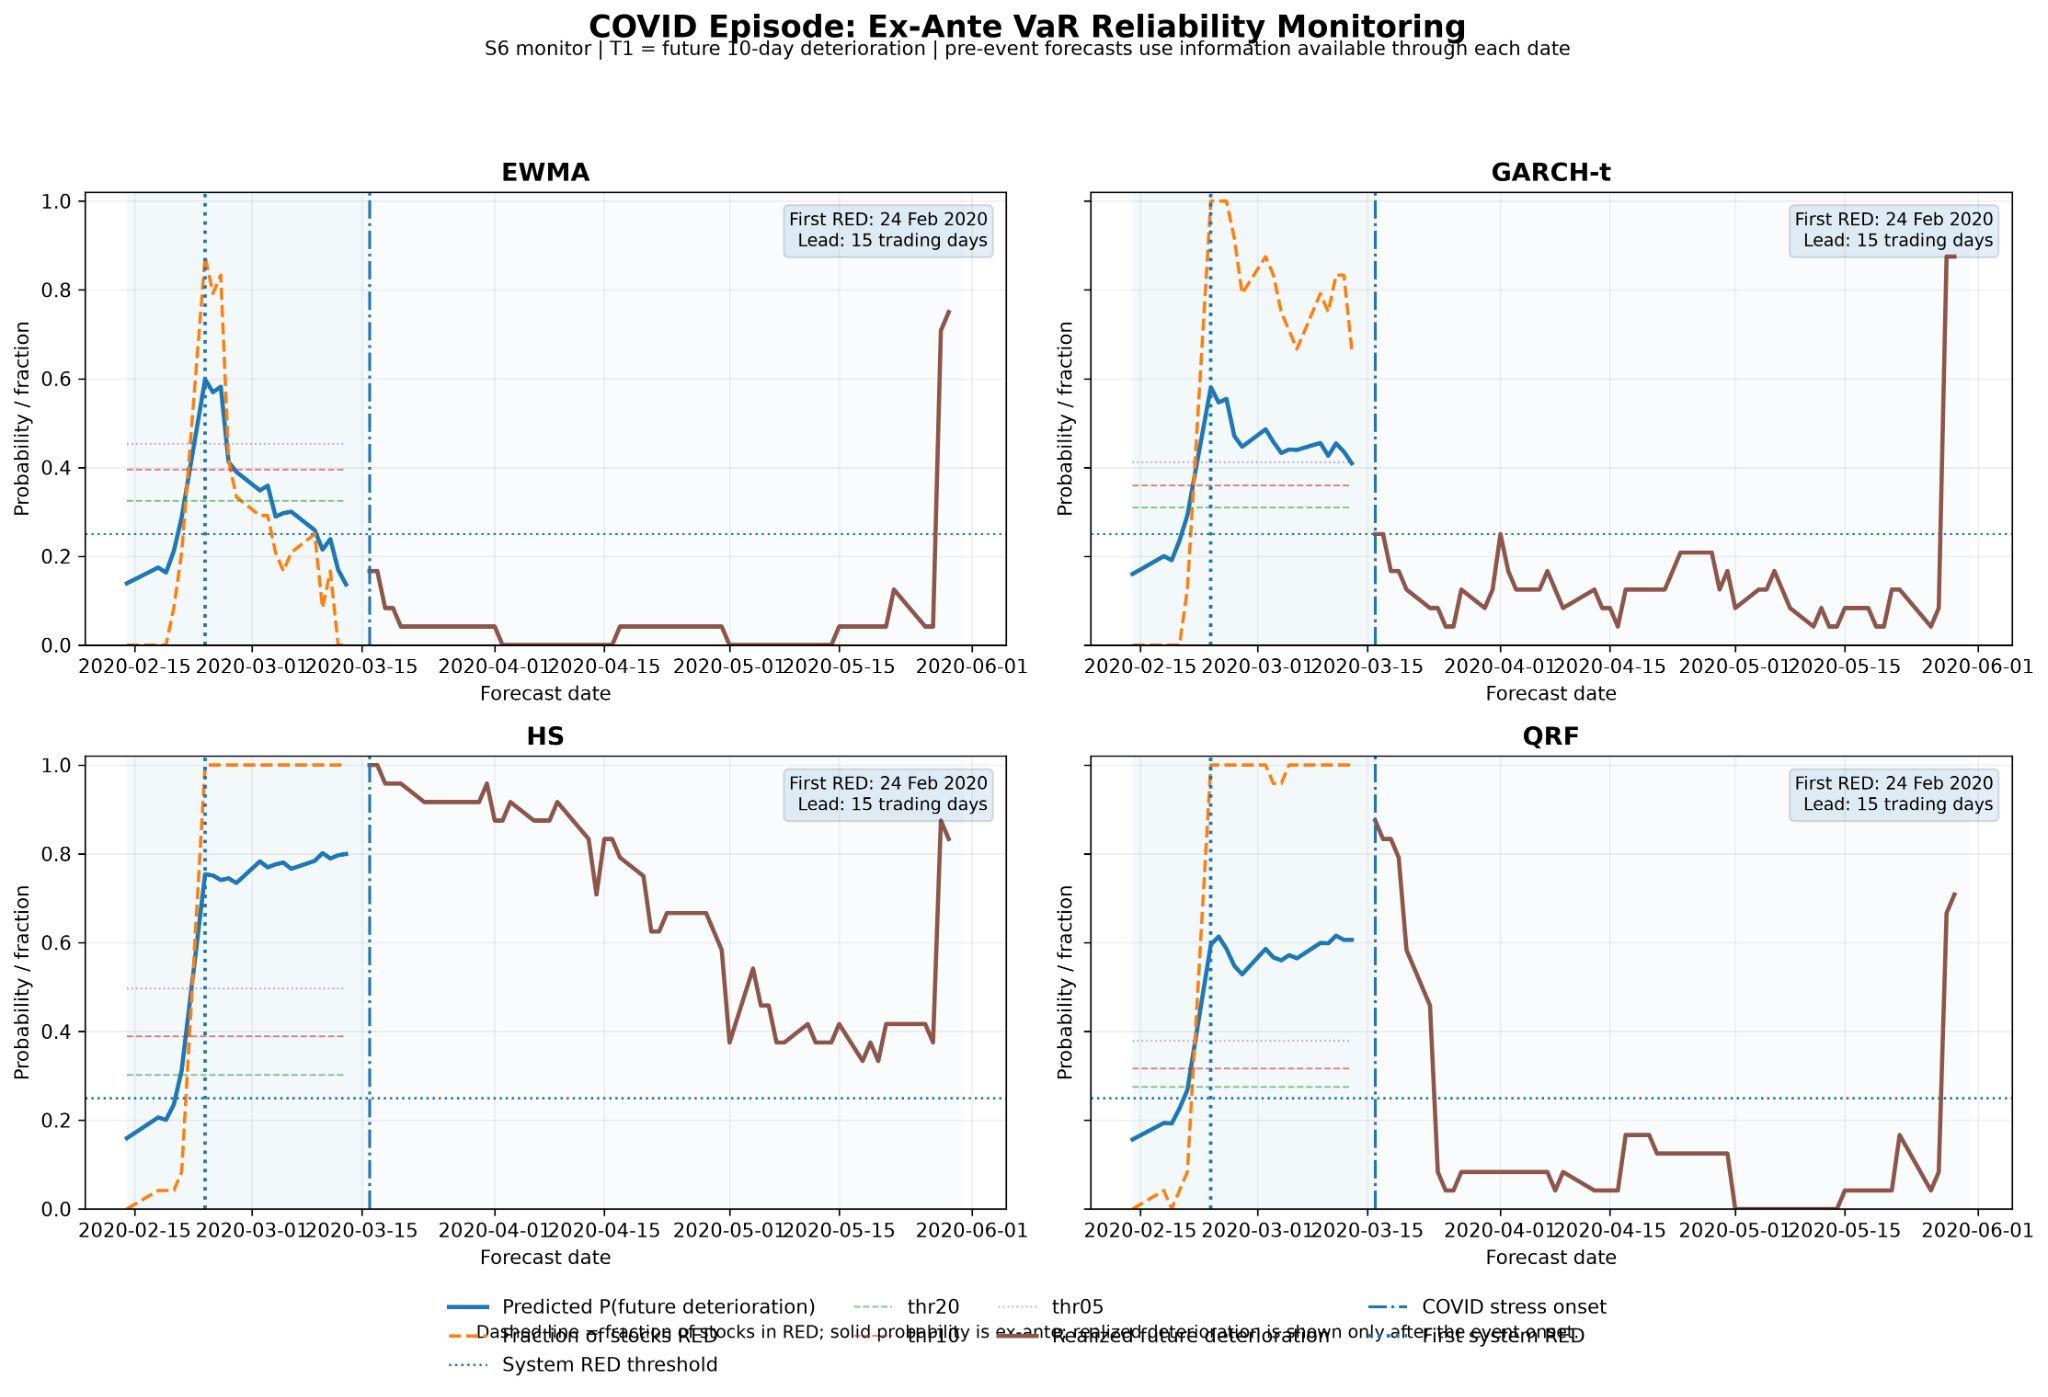

In [ ]:
# Embedded final T1 figure

### T1 interpretation

The case study is striking because the alert occurs **before** the fixed COVID stress onset for every model.

At the first system RED date:

- EWMA: P(deterioration) ≈ **0.598**
- GARCH-t: ≈ **0.581**
- HS: ≈ **0.754**
- QRF: ≈ **0.595**

The realized deterioration later becomes large:

- EWMA maximum post-onset deterioration: **75%**
- GARCH-t: **91.7%**
- HS: **100%**
- QRF: **87.5%**

The correct claim is **not** that the monitor “predicted COVID.” It detected an emerging reliability deterioration pattern **before a fixed, externally defined stress onset**.


# 5. Final COVID T2 case study — coverage failure

T2 uses a different event anchor because it measures a different phenomenon.

The final T2 figure uses:

**coverage-failure onset = 12 February 2020**

The first system RED alerts occur:

- EWMA: **24 January 2020 — 13 trading days lead**
- GARCH-t: **27 January 2020 — 12 trading days lead**
- HS: **27 January 2020 — 12 trading days lead**
- QRF: **27 January 2020 — 12 trading days lead**

All four therefore detect the T2 event before onset.


In [ ]:
# Final T2 paper table
t2 = pd.read_csv("/mnt/data/RS05_COVID_T2_FINAL_PAPER_TABLE_S6.csv")
display(t2)


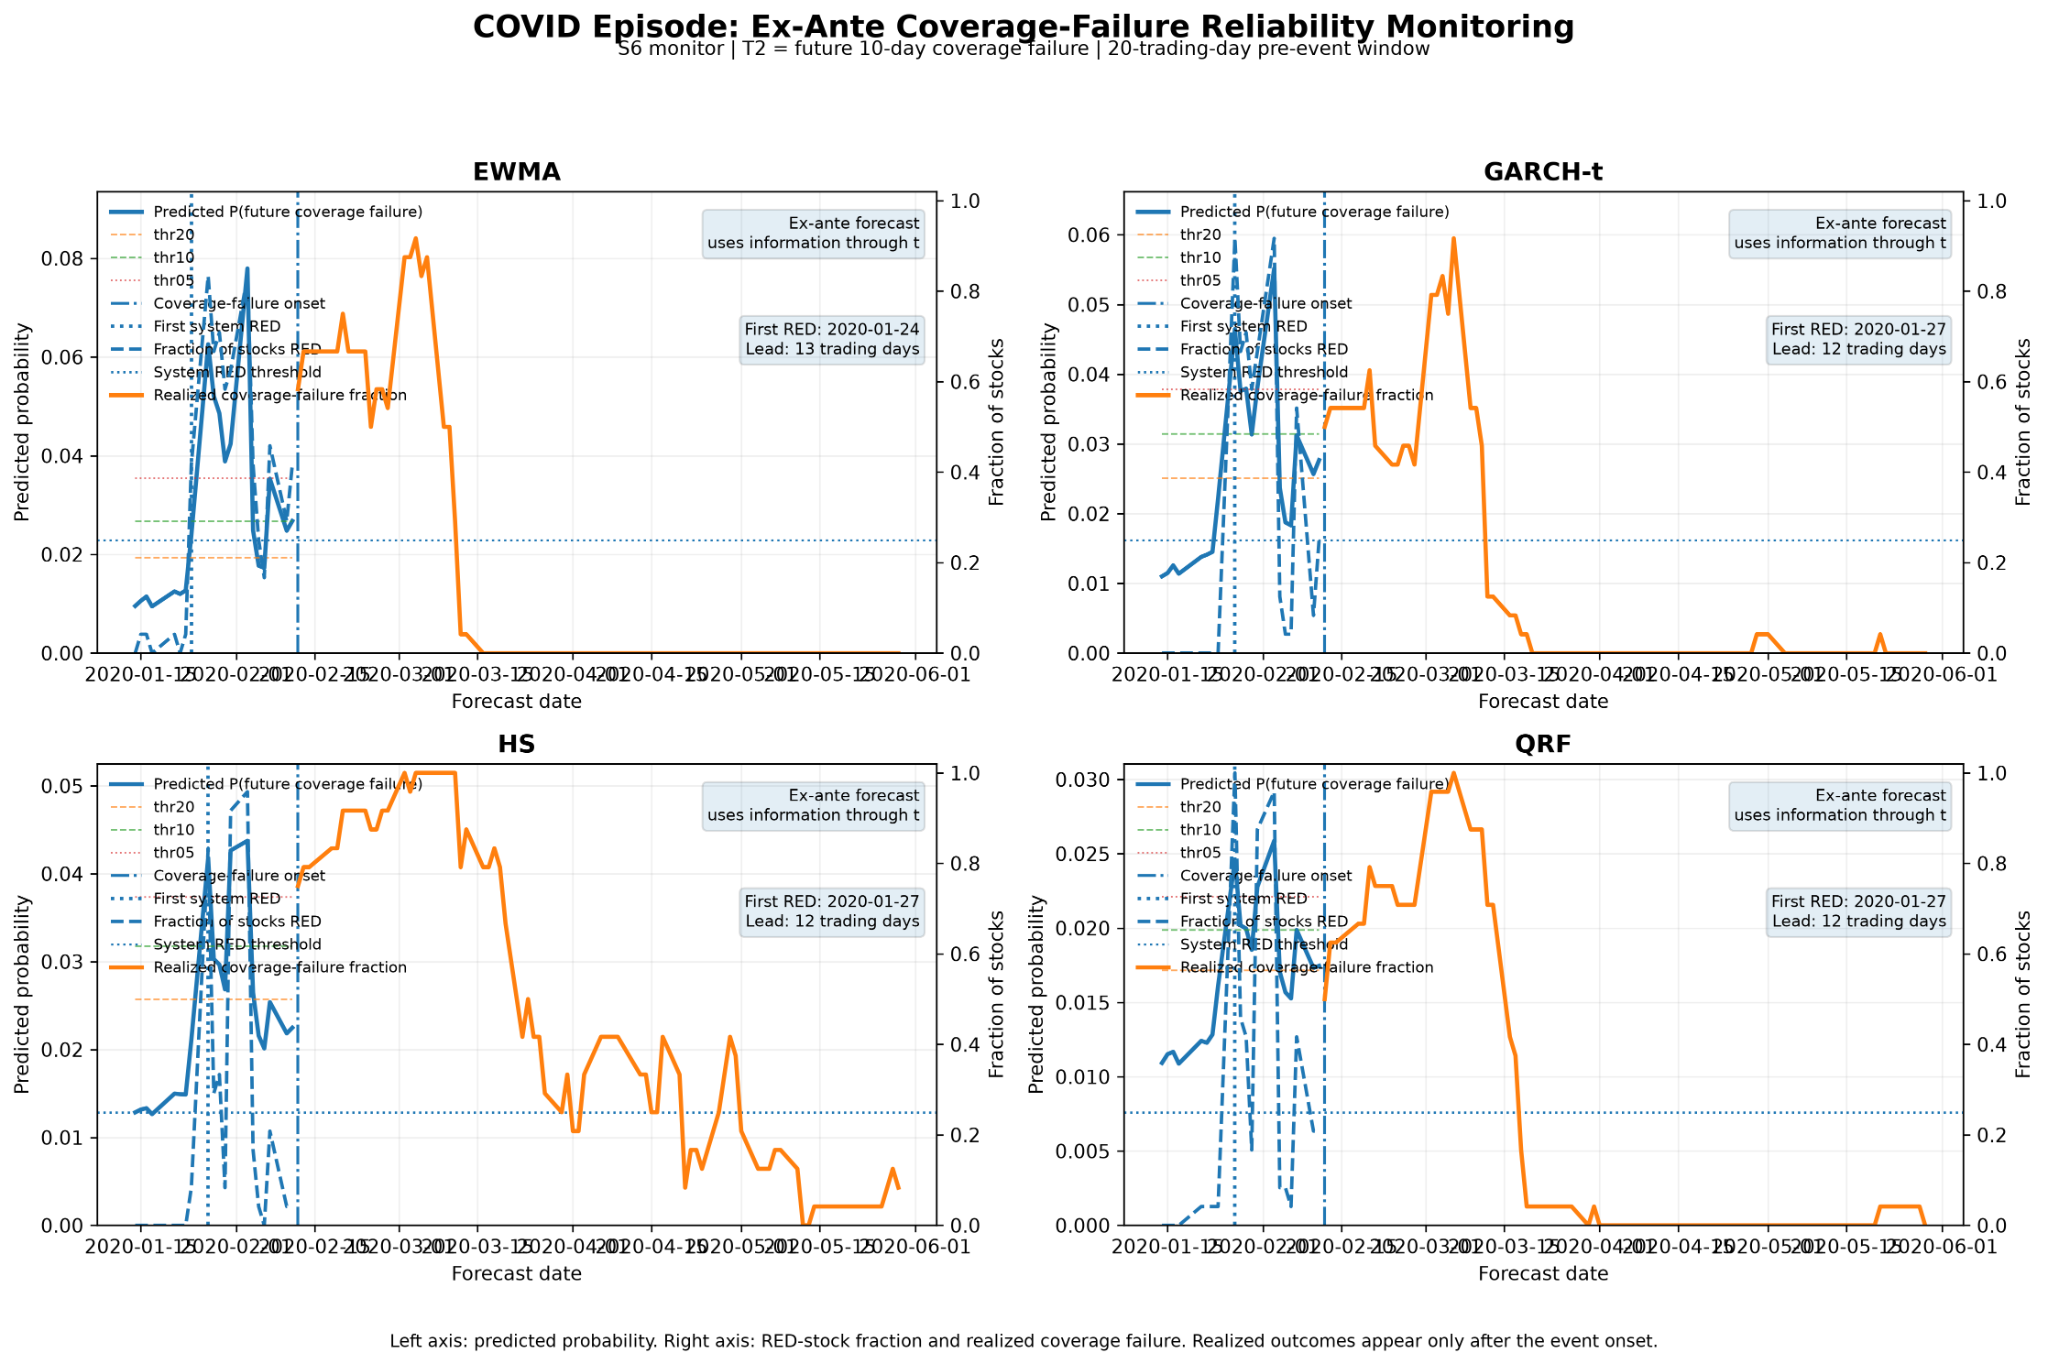

In [ ]:
# Embedded final T2 figure

### T2 interpretation

T2 demonstrates that the system can also issue a pre-event reliability warning for future coverage failure.

However, the probability scale is much lower than T1 because coverage failure is a rarer / more specific target. The important quantity is therefore not simply whether probabilities are numerically large; it is whether the forecasts discriminate future failures and whether the system alert occurs before the fixed onset.

This is why the threshold-free evaluation below is essential.


# 6. Threshold-free comparison against conventional backtests

The final comparison converts conventional backtest diagnostics into continuous scores available at date *t*:

| Score | Meaning |
|---|---|
| `bt_count250` | rolling 250-day breach count |
| `bt_count60` | rolling 60-day breach count |
| `bt_count20` | rolling 20-day breach count |
| `kupiec250` | 250-day Kupiec unconditional-coverage LR |
| `christoffersen250` | 250-day Christoffersen conditional-coverage LR |

The implementation uses breaches realized through date *t* only.

For each score we calculate:

- ROC AUC
- PR-lift
- S6 − score AUC difference
- S4 − score AUC difference
- 20-trading-day date-block bootstrap confidence interval

The final run shown here used **500 bootstrap replicates**.


In [ ]:
# Final 500-bootstrap AUC results from the completed RS05 run
models = ["EWMA", "GARCH-t", "HS", "QRF"]
scores = ["S6","S4","bt_count250","bt_count60","bt_count20","kupiec250","christoffersen250"]

t1_auc = pd.DataFrame({
    "Model": models,
    "S6": [0.6485,0.5926,0.7139,0.5733],
    "S4": [0.6364,0.5724,0.6924,0.5562],
    "bt_count250": [0.4589,0.5097,0.5804,0.5094],
    "bt_count60": [0.4503,0.4927,0.6502,0.5230],
    "bt_count20": [0.4904,0.5084,0.6527,0.5290],
    "kupiec250": [0.4796,0.4923,0.5253,0.4821],
    "christoffersen250": [0.4828,0.4919,0.5231,0.4822],
}).set_index("Model")

display(t1_auc)


# 7. T1 is the strongest statistical result

### T1 AUC

| Model | S6 | S4 | Best standard comparator |
|---|---:|---:|---:|
| EWMA | **0.6485** | 0.6364 | 0.4904 |
| GARCH-t | **0.5926** | 0.5724 | 0.5084 |
| HS | **0.7139** | 0.6924 | 0.6527 |
| QRF | **0.5733** | 0.5562 | 0.5290 |

S6 beats every conventional score for every model.

More importantly, the date-block bootstrap says the T1 S6-minus-score confidence interval is above zero for **all 20 model/comparator comparisons** in the 500-replicate run.

That is much stronger evidence than simply reporting that the COVID case-study alert occurred before the event.


In [ ]:
t1_diffs = pd.DataFrame({
    "Baseline": ["bt_count20","bt_count250","bt_count60","christoffersen250","kupiec250"],
    "EWMA": [0.1581,0.1897,0.1982,0.1657,0.1689],
    "GARCH-t": [0.0842,0.0829,0.0999,0.1007,0.1003],
    "HS": [0.0612,0.1334,0.0636,0.1907,0.1885],
    "QRF": [0.0443,0.0638,0.0503,0.0911,0.0911],
    "Pooled mean": [0.0869,0.1175,0.1030,0.1371,0.1372],
}).set_index("Baseline")
display(t1_diffs)

t1_ci = pd.DataFrame({
    "Baseline": ["bt_count20","bt_count250","bt_count60","christoffersen250","kupiec250"],
    "EWMA": [True]*5,
    "GARCH-t": [True]*5,
    "HS": [True]*5,
    "QRF": [True]*5,
}).set_index("Baseline")
display(t1_ci.rename(columns=lambda c: c + " — 95% CI above 0"))


# 8. S4 versus S6 — what is the monitor actually learning?

This is the important ablation.

### S4

S4 is the strong baseline information set.

### S6

S6 adds the model-state / model-specific information.

The final T1 results show:

> **S6 > S4 > standard backtest scores**

in the overall pattern.

That means we should not claim that all predictive value comes from model-state information. Much of the gain already exists in S4's broader market/volatility/persistence information.

But S6 consistently improves AUC over S4 in the final T1 table:

- EWMA: **+0.0121**
- GARCH-t: **+0.0202**
- HS: **+0.0215**
- QRF: **+0.0171**

So the model-specific layer provides an additional increment.


In [ ]:
s4_s6 = pd.DataFrame({
    "Model": models,
    "S4 AUC": [0.6364,0.5724,0.6924,0.5562],
    "S6 AUC": [0.6485,0.5926,0.7139,0.5733],
})
s4_s6["S6 - S4"] = s4_s6["S6 AUC"] - s4_s6["S4 AUC"]
display(s4_s6)


# 9. T2 threshold-free result — mixed by design

The final T2 AUC table is:

| Model | S6 | S4 | `bt_count20` |
|---|---:|---:|---:|
| EWMA | 0.5415 | 0.5195 | **0.6359** |
| GARCH-t | 0.5410 | 0.5412 | **0.6467** |
| HS | 0.7269 | 0.7267 | **0.7847** |
| QRF | 0.6265 | 0.6077 | **0.7255** |

Thus T2 does **not** support the claim that S6 universally dominates conventional breach-count diagnostics.

The bootstrap reinforces this:

- HS is significantly better than several conventional scores.
- Most EWMA/GARCH-t/QRF differences are not significantly above zero.
- Some short-window breach-count scores are actually stronger.

### How to present this

Say:

> “The monitor's incremental advantage is target-dependent. The deterioration target shows a clear and broad advantage over conventional backtest scores, while coverage-failure prediction is more competitive with existing breach-history diagnostics.”

That is a stronger scientific statement than trying to hide the mixed T2 result.


In [ ]:
t2_auc = pd.DataFrame({
    "Model": models,
    "S6": [0.5415,0.5410,0.7269,0.6265],
    "S4": [0.5195,0.5412,0.7267,0.6077],
    "bt_count250": [0.5359,0.5517,0.6430,0.6127],
    "bt_count60": [0.5520,0.5808,0.7599,0.6566],
    "bt_count20": [0.6359,0.6467,0.7847,0.7255],
    "kupiec250": [0.4711,0.4743,0.4963,0.4803],
    "christoffersen250": [0.5090,0.4648,0.5179,0.4677],
}).set_index("Model")
display(t2_auc)

t2_diffs = pd.DataFrame({
    "Baseline": ["bt_count20","bt_count250","bt_count60","christoffersen250","kupiec250"],
    "EWMA": [-0.0943,0.0056,-0.0104,0.0326,0.0705],
    "GARCH-t": [-0.1057,-0.0107,-0.0398,0.0762,0.0667],
    "HS": [-0.0578,0.0839,-0.0330,0.2090,0.2306],
    "QRF": [-0.0990,0.0138,-0.0301,0.1588,0.1462],
    "Pooled mean": [-0.0892,0.0232,-0.0283,0.1191,0.1285],
}).set_index("Baseline")
display(t2_diffs)


# 10. Why the date-block bootstrap matters

The observations are not independent ticker-by-ticker in a normal i.i.d. sense.

A market regime creates serial dependence across dates and common dependence across assets.

Therefore the final comparison resamples **20-trading-day date blocks** rather than individual rows.

For each bootstrap replicate:

1. sample circular date blocks,
2. assign the resulting date multiplicities to every observation on those dates,
3. calculate the AUC for the monitor and comparator,
4. store the AUC difference,
5. use the 2.5th and 97.5th percentiles for the confidence interval.

The final source code explicitly describes this as a **date-block bootstrap of AUC differences**.


# 11. Calibration and trust-band interpretation

The reliability output should **not** be interpreted as a literal probability that “VaR will fail.”

A safer interpretation is:

> **At date t, the monitor estimates the likelihood that the model will enter a predefined future reliability-deterioration state over the next H=10 trading days, under the frozen target definition.**

The probability is useful because it provides a continuous ranking signal.

The trust bands are operational states:

- **GREEN:** lower concern
- **AMBER:** elevated concern
- **RED:** high concern

A system-level RED alert requires at least 25% of the 24 monitored stocks to be RED.

The final COVID figures show that these states can be aggregated into an interpretable portfolio/model warning.


# 12. Leakage / ex-ante defense

If the professor asks **“How do you know this is not look-ahead bias?”**, answer:

> “The event dates are fixed independently of the monitor output. For every forecast date t, the monitor uses only information available through t. The realized deterioration or coverage failure is only plotted after the event onset for evaluation. In the standard-backtest comparison, the comparator scores also use only breaches realized through the forecast date.”

The final case-study implementation explicitly states that it:

- does not retrain RS05,
- does not recalibrate probabilities,
- does not estimate new thresholds,
- does not use future outcomes as predictors,
- does not choose the event onset from monitor probabilities,
- does not choose the alert date by looking for the largest probability spike.

That is the core ex-ante integrity argument.


# 13. What NOT to claim

### Do not say

> “The model predicted the COVID crash.”

The system is not a crash predictor.

### Say instead

> “The reliability layer provided an ex-ante warning of future VaR deterioration before a fixed COVID stress onset.”

### Do not say

> “S6 always beats traditional backtests.”

T2 does not support that.

### Say instead

> “For the deterioration target, S6 provides a broad and statistically supported incremental signal over conventional rolling backtest diagnostics; the coverage-failure target is more competitive with breach-history statistics.”

### Do not say

> “The predicted probability is the probability that VaR is wrong.”

### Say

> “It is the calibrated probability of the predefined future reliability target over the specified horizon.”


# 14. Main limitations

1. **Effective sample size is smaller than the raw row count.** Market dates create substantial dependence.
2. **T1 is the strongest result; T2 is mixed.**
3. The COVID case study is one major episode and should remain **illustrative**, not the sole statistical validation.
4. The 500-replicate bootstrap shown here is appropriate for the current validation run, but a final paper version can rerun the exact experiment at **B=1000** for smoother percentile estimates.
5. The reliability target is predefined and operational; changing the target definition can change the result.
6. The system is a **monitoring layer on top of existing VaR models**, not a replacement for VaR itself.


# 15. Professor explanation — 60 seconds

> **“The problem is that VaR backtesting is usually backward-looking. It tells us whether a model has already been failing, but it does not give us an early-warning signal that the model is becoming unreliable.**
>
> **So we built a causal reliability layer on top of four existing 5% VaR models: EWMA, GARCH-t, Historical Simulation and QRF. The monitor predicts whether the model will experience a predefined reliability deterioration over the next 10 trading days.**
>
> **We compare two information sets. S4 is our strong baseline, while S6 additionally contains model-specific state information.**
>
> **For the COVID case study, the event dates are fixed independently of the monitor. Every model produced a system RED alert 12–15 trading days before the relevant event onset.**
>
> **But the stronger test is the full 2020+ threshold-free comparison. We turn conventional rolling breach counts and Kupiec/Christoffersen statistics into continuous scores and compare them against the same future labels. For T1, S6 beats every conventional score for every model, and the 20-day date-block bootstrap confidence intervals are above zero in all of those comparisons.**
>
> **T2 is more mixed, especially against short-window breach counts, so we do not claim universal superiority. The conclusion is that the reliability layer provides a strong incremental early-warning signal specifically for future deterioration, while coverage-failure prediction is more competitive with conventional breach-history diagnostics.”**


# 16. Professor questions — short answers

### Why not just use rolling breach counts?

Because they summarize **realized historical failures**. The monitor is designed to predict a **future reliability state**.

### Why do you need S4 if S6 is the final model?

S4 is an ablation/control. It tells us whether the apparent gain is coming from general market conditions versus model-specific state.

### Why is T1 stronger than T2?

The targets represent different failure modes. T1 captures deterioration as a broader reliability-state transition, while T2 is specifically coverage failure. The final evidence shows that conventional breach-history diagnostics are more competitive for T2.

### Why use AUC?

The system is fundamentally a ranking/early-warning system. AUC measures whether higher monitor scores correspond to a higher probability of the future target without choosing one arbitrary operating threshold.

### Why PR-lift as well?

The target is relatively uncommon, so precision-recall behavior is informative. PR-lift compares average precision with the target prevalence.

### Why bootstrap by date blocks?

Because financial time series have serial and cross-sectional dependence. Resampling individual rows would understate uncertainty.

### Did the monitor see the future COVID outcome?

No. The event is fixed independently, and the pre-event monitor uses information available through each forecast date only.

### What is the strongest result?

T1: **S6 AUC 0.573–0.714 across the four models, versus substantially lower conventional-score AUCs, with every S6-minus-score bootstrap CI above zero in the final 500-replicate run.**


# 17. Final research claim

## Defensible headline

> **A causal reliability-monitoring layer can provide statistically significant incremental early-warning information about future VaR deterioration beyond conventional rolling backtest diagnostics.**

## More precise version

> **In the final RS05 T1 evaluation, the S6 monitor consistently outperformed continuous rolling backtest diagnostics across EWMA, GARCH-t, HS and QRF, with date-block bootstrap confidence intervals for the AUC advantage above zero. The S4 ablation also outperformed standard diagnostics, while S6 provided a further incremental improvement over S4. Coverage-failure prediction showed more mixed results, indicating that the benefit is target-dependent rather than universally dominant.**

That is the statement I would put in the paper.


# Appendix A — Final COVID headline numbers

### T1

- Fixed onset: **2020-03-16**
- First system RED: **2020-02-24 for all four models**
- Lead: **15 trading days for all four**
- All four detected before onset.
- Maximum post-onset deterioration: **75.0%–100.0%**

### T2

- Fixed onset: **2020-02-12**
- First system RED:
  - EWMA: **2020-01-24**
  - GARCH-t: **2020-01-27**
  - HS: **2020-01-27**
  - QRF: **2020-01-27**
- Lead: **12–13 trading days**
- All four detected before onset.
- Maximum post-onset coverage failure: **91.7%–100.0%**


# Appendix B — Final files used for this notebook

### Final RS05 implementation

`src/experiments/regime_shifts/rs05/`

### Final output artifacts

- `RS05_COVID_T1_FINAL_PAPER_TABLE_S6.csv`
- `RS05_COVID_T1_FINAL_PAPER_FIGURE_S6.pdf`
- `RS05_COVID_T2_FINAL_PAPER_TABLE_S6.csv`
- `RS05_COVID_T2_FINAL_PAPER_FIGURE_S6.pdf`
- `RS05_COVID_T1_corrected_summary_S6.csv`
- `RS05_COVID_T2_corrected_summary_S6.csv`
- `RS05_COVID_corrected_lead_time_S6.csv`
- `RS05_COVID_corrected_date_level_S6.csv`
- `RS05_COVID_corrected_summary_S6.csv`

### Final statistical comparison

- `model_specificity_v2.py`
- `backtest_scores_vs_monitor.py`

The numerical tables in this notebook reproduce the **completed 500-bootstrap run** supplied with the final project state.


# Appendix C — Final status

| Component | Status |
|---|---|
| Causal/ex-ante COVID T1 case study | **Strong** |
| T1 lead-time evidence | **Strong** |
| T1 monitor vs conventional backtests | **Strong** |
| T1 S6 vs S4 ablation | **Positive incremental gain** |
| T2 COVID case study | **Positive** |
| T2 monitor vs conventional backtests | **Mixed / target-dependent** |
| Date-block bootstrap | **Implemented; 500-replicate final run shown** |
| Leakage defense | **Explicit in final implementation** |
| Main paper claim | **Ready, with T1 as headline** |
